# Quantum Minesweeper: The Superposition Challenge

**Track:** Quantum Games & Interactive Puzzles  
**Tools:** Qiskit, Qiskit Aer, NumPy, Matplotlib

This notebook demonstrates quantum state preparation and measurement for generating a 3?3 Minesweeper board.

**Honest limitation:** This is a quantum sampling demonstration, not a quantum speedup. A classical random-number generator can produce the same probability distribution.

## 1. Imports

We use Qiskit Aer to simulate quantum measurements on our computer.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator

BOARD_SIZE = 3
CELL_COUNT = BOARD_SIZE ** 2

print("Imports successful")
print("Board size:", BOARD_SIZE, "x", BOARD_SIZE)
print("Qubits:", CELL_COUNT)

Imports successful
Board size: 3 x 3
Qubits: 9


## 2. Prepare the quantum circuit

The RY gate prepares a qubit so that the probability of measuring 1 is p. Here, 1 means mine and 0 means safe.

The rotation angle is ? = 2 arcsin(?p).

In [2]:
def build_board_circuit(p=0.25):
    if not 0 <= p <= 1:
        raise ValueError("p must be between 0 and 1")
    qc = QuantumCircuit(CELL_COUNT, CELL_COUNT)
    theta = 2 * math.asin(math.sqrt(p))
    for q in range(CELL_COUNT):
        qc.ry(theta, q)
    qc.measure(range(CELL_COUNT), range(CELL_COUNT))
    return qc

circuit = build_board_circuit(0.25)
print(circuit.draw(output="text"))

     ┌─────────┐┌─┐                        
q_0: ┤ Ry(π/3) ├┤M├────────────────────────
     ├─────────┤└╥┘┌─┐                     
q_1: ┤ Ry(π/3) ├─╫─┤M├─────────────────────
     ├─────────┤ ║ └╥┘┌─┐                  
q_2: ┤ Ry(π/3) ├─╫──╫─┤M├──────────────────
     ├─────────┤ ║  ║ └╥┘┌─┐               
q_3: ┤ Ry(π/3) ├─╫──╫──╫─┤M├───────────────
     ├─────────┤ ║  ║  ║ └╥┘┌─┐            
q_4: ┤ Ry(π/3) ├─╫──╫──╫──╫─┤M├────────────
     ├─────────┤ ║  ║  ║  ║ └╥┘┌─┐         
q_5: ┤ Ry(π/3) ├─╫──╫──╫──╫──╫─┤M├─────────
     ├─────────┤ ║  ║  ║  ║  ║ └╥┘┌─┐      
q_6: ┤ Ry(π/3) ├─╫──╫──╫──╫──╫──╫─┤M├──────
     ├─────────┤ ║  ║  ║  ║  ║  ║ └╥┘┌─┐   
q_7: ┤ Ry(π/3) ├─╫──╫──╫──╫──╫──╫──╫─┤M├───
     ├─────────┤ ║  ║  ║  ║  ║  ║  ║ └╥┘┌─┐
q_8: ┤ Ry(π/3) ├─╫──╫──╫──╫──╫──╫──╫──╫─┤M├
     └─────────┘ ║  ║  ║  ║  ║  ║  ║  ║ └╥┘
c: 9/════════════╩══╩══╩══╩══╩══╩══╩══╩══╩═
                 0  1  2  3  4  5  6  7  8 


## 3. Measure one board

The simulator samples one outcome. Qiskit displays bitstrings with the highest classical bit first, so we reverse the string to map it to board cells 0?8.

In [3]:
simulator = AerSimulator()
compiled = transpile(circuit, simulator)
result = simulator.run(compiled, shots=1, seed_simulator=42).result()
bitstring = next(iter(result.get_counts()))

board = [int(bitstring[-1-i]) for i in range(CELL_COUNT)]
board_grid = np.array(board).reshape(BOARD_SIZE, BOARD_SIZE)

print("Measured bitstring:", bitstring)
print("0 = safe, 1 = mine")
print(board_grid)
print("Mines in this board:", sum(board))

Measured bitstring: 100000000
0 = safe, 1 = mine
[[0 0 0]
 [0 0 0]
 [0 0 1]]
Mines in this board: 1


## 4. Visualize the board

This plot displays the sampled result. It is one possible outcome, not a fixed prediction.

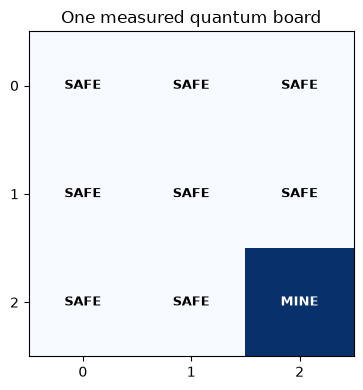

In [4]:
fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(board_grid, cmap="Blues", vmin=0, vmax=1)
for r in range(BOARD_SIZE):
    for c in range(BOARD_SIZE):
        label = "MINE" if board_grid[r, c] else "SAFE"
        ax.text(c, r, label, ha="center", va="center",
                color="white" if board_grid[r, c] else "black",
                fontsize=9, fontweight="bold")
ax.set_xticks(range(BOARD_SIZE))
ax.set_yticks(range(BOARD_SIZE))
ax.set_title("One measured quantum board")
plt.tight_layout()
plt.show()

## 5. Test the probability

Over many measurements, the observed fraction of 1 outcomes should approach the target probability. The exact fraction varies due to randomness.

In [5]:
p = 0.25
shots = 2000
single = QuantumCircuit(1, 1)
single.ry(2 * math.asin(math.sqrt(p)), 0)
single.measure(0, 0)

counts = simulator.run(
    transpile(single, simulator), shots=shots, seed_simulator=123
).result().get_counts()

observed = counts.get("1", 0) / shots
print("Measurement counts:", counts)
print("Target mine probability:", p)
print("Observed fraction of mines:", round(observed, 3))

Measurement counts: {'0': 1504, '1': 496}
Target mine probability: 0.25
Observed fraction of mines: 0.248


## 6. Compare with a classical sampler

Both methods target the same Bernoulli probability. This is a distribution comparison, not a speed benchmark or evidence of quantum advantage.

In [6]:
p = 0.25
samples = 2000

quantum_counts = simulator.run(
    transpile(single, simulator), shots=samples, seed_simulator=7
).result().get_counts()
quantum_mines = quantum_counts.get("1", 0)

rng = np.random.default_rng(7)
classical_mines = int(rng.binomial(samples, p))

print(f"Quantum circuit: {quantum_mines}/{samples} outcomes were mines")
print(f"Classical sampler: {classical_mines}/{samples} outcomes were mines")
print("Both approximate the same probability distribution.")

Quantum circuit: 504/2000 outcomes were mines
Classical sampler: 500/2000 outcomes were mines
Both approximate the same probability distribution.


## 7. Limitations and conclusion

- This notebook uses a simulator, not physical quantum hardware.
- Qubits are independent; there is no entanglement.
- The complete board is measured at the start of a game. Clicking a tile reveals its stored result; it does not remeasure that qubit.
- Classical code computes neighboring-mine clues and handles gameplay.
- No quantum speedup is claimed; a classical sampler can reproduce this distribution.

**Conclusion:** The project uses Qiskit state preparation and measurement to create an interactive puzzle while distinguishing quantum sampling from classical game logic.